# Main paper figures from saved arrays

Plots the six main/SM figures purely from the `.npy` arrays in this directory --- no
Hamilton drivers, no simulation. Meant for a side-by-side check against
`simulation_old.ipynb`, which originally ran the simulation and produced the committed
figures.

Data provenance:

- `new_qfi.npy`, `new_qfi_inv.npy`, `coordinates.npy` --- regenerated by
  `simulate_bounds.py` at HEAD (verified to match the legacy `qfi.npy` to ~1e-13).
- `fi_ms_-1.npy`, `fi_ms_inv_-1_with_remainder.npy` --- committed mode-sorting results
  for the four dominant modes (0,0), (1,0), (2,0), (0,2) plus the remainder channel
  (last channel index).
- `fi_di.npy`, `fi_di_inv.npy` --- committed direct-imaging results.

Set `SAVE = True` to overwrite the committed `*_optimal_remainder.pdf` figures with the
regenerated ones; it is off by default so the two notebooks can be compared safely.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from rayfish.visualize_helpers import create_fig_and_ax, latexify, plot_individual_fi

In [2]:
n_grids = 50

coords = np.load("coordinates.npy")
p_range = -coords[0, :, 6]
x_range = coords[:, 0, 2]

qfi_ = np.load("new_qfi.npy")
qfi_inv_ = np.load("new_qfi_inv.npy")

fi_ms_ = np.load("fi_ms_-1.npy")  # (50, 50, 5, 2, 2): 4 dominant modes + remainder
fi_ms_inv_ = np.load("fi_ms_inv_-1_with_remainder.npy")

fi_di_ = np.load("fi_di.npy")
fi_di_inv_ = np.load("fi_di_inv.npy")

In [ ]:
%matplotlib inline
latexify()

FORMAT = "pdf"
SAVE = False


def save_figure(fig, name) -> None:  # noqa: ANN001
    """Write the canonical figure file only when explicitly enabled."""
    if SAVE:
        fig.savefig(f"{name}.{FORMAT}", format=FORMAT, bbox_inches="tight")

In [4]:
# Whitelist of continuous colormaps suitable for publication
continuous_cmaps = [
    "Greens",
    "Reds",
    "Purples",
    "Oranges",
    "plasma",
    "viridis",
    "cividis",
    "magma",
    "inferno",
    "turbo",
    "pink",
    "bone",
    "gray",
    "copper",
    "Blues",
]


def filter_pub_friendly_continuous(
    max_rgb: float = 1, sample_points: int = 256
) -> list:
    """Good colors for plots."""
    good_cmaps = []
    for name in continuous_cmaps:
        cmap = plt.get_cmap(name)
        colors = cmap(np.linspace(0, 1, sample_points))[:, :3]  # RGB only
        if np.any(colors > max_rgb):
            continue  # skip overly bright colors
        good_cmaps.append(name)
    return good_cmaps

# s param

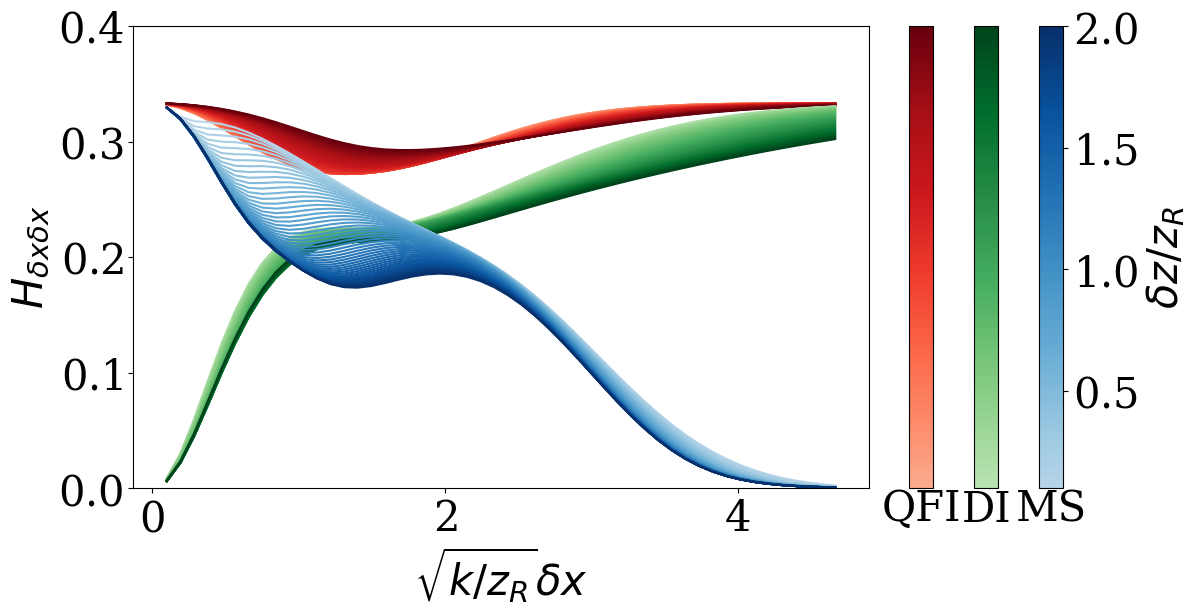

In [5]:
fig, axs = create_fig_and_ax(3)
qfi_cm = plot_individual_fi(
    fig, axs, qfi_[:, :, 0, 0], x_range, p_range, "Reds", 1, "QFI"
)
di_cm = plot_individual_fi(
    fig, axs, fi_di_[:, :, 0, 0], x_range, p_range, "Greens", 2, "DI"
)
ms_cm = plot_individual_fi(
    fig,
    axs,
    np.sum(fi_ms_, axis=2)[:, :, 0, 0],
    x_range,
    p_range,
    "Blues",
    3,
    "MS",
    False,
)

axs[0].set_ylim(0, 0.4)
axs[3].set_ylabel(r"$\delta z / z_R$")
axs[0].set_xlabel(r"$\sqrt{k/z_R} \delta x$")
axs[0].set_ylabel(r"$H_{\delta x \delta x}$")

save_figure(fig, "s_param_fi_comparison_optimal_remainder")
plt.show()

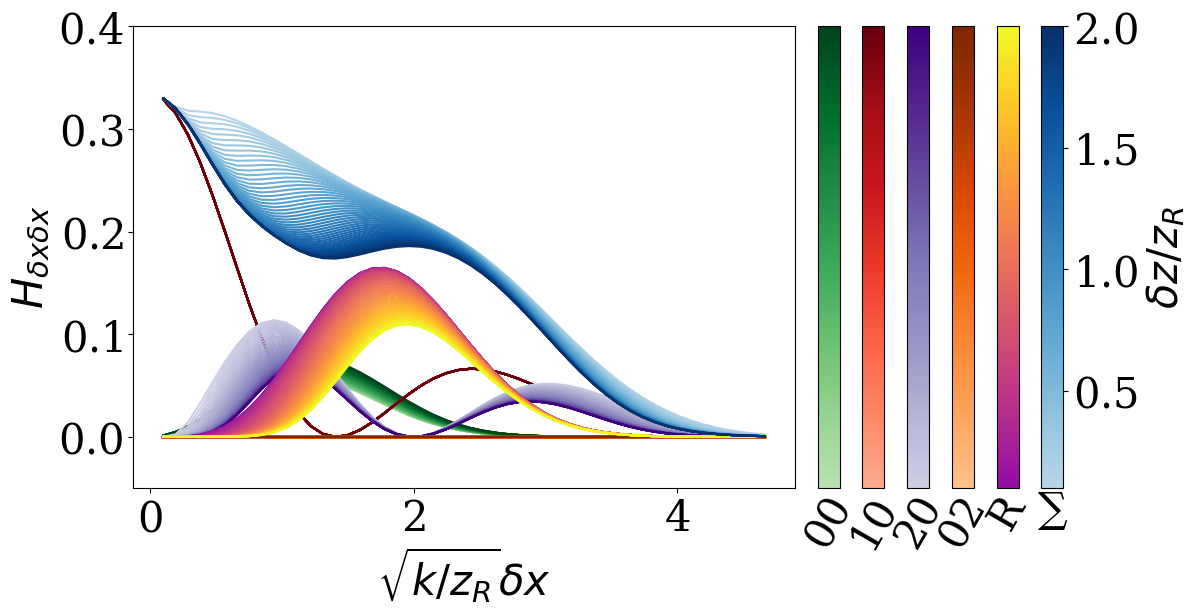

In [6]:
good_cmaps = filter_pub_friendly_continuous()
IMPORTANT_MODES = ((0, 0), (1, 0), (2, 0), (0, 2))

n_axes = len(IMPORTANT_MODES) + 1
fig, axs = create_fig_and_ax(n_axes + 1)

for idx, mode in enumerate(IMPORTANT_MODES):
    (i, j) = mode
    plot_individual_fi(
        fig,
        axs,
        fi_ms_[:, :, idx, 0, 0],
        x_range,
        p_range,
        good_cmaps[idx],
        idx + 1,
        f"{i}{j}",
        rotation=60,
    )

plot_individual_fi(
    fig,
    axs,
    fi_ms_[:, :, -1, 0, 0],
    x_range,
    p_range,
    good_cmaps[len(IMPORTANT_MODES)],
    len(IMPORTANT_MODES) + 1,
    r"R",
    rotation=60,
)

sum_cm = plot_individual_fi(
    fig,
    axs,
    np.sum(fi_ms_, axis=2)[:, :, 0, 0],
    x_range,
    p_range,
    good_cmaps[-1],
    n_axes + 1,
    "∑",
    False,
)


axs[0].set_ylim(-0.05, 0.4)
axs[n_axes + 1].set_ylabel(r"$\delta z / z_R$")
axs[0].set_xlabel(r"$\sqrt{k/z_R} \delta x$")
axs[0].set_ylabel(r"$H_{\delta x \delta x}$")

save_figure(fig, "s_param_individual_mode_contributions_optimal_remainder")
plt.show()

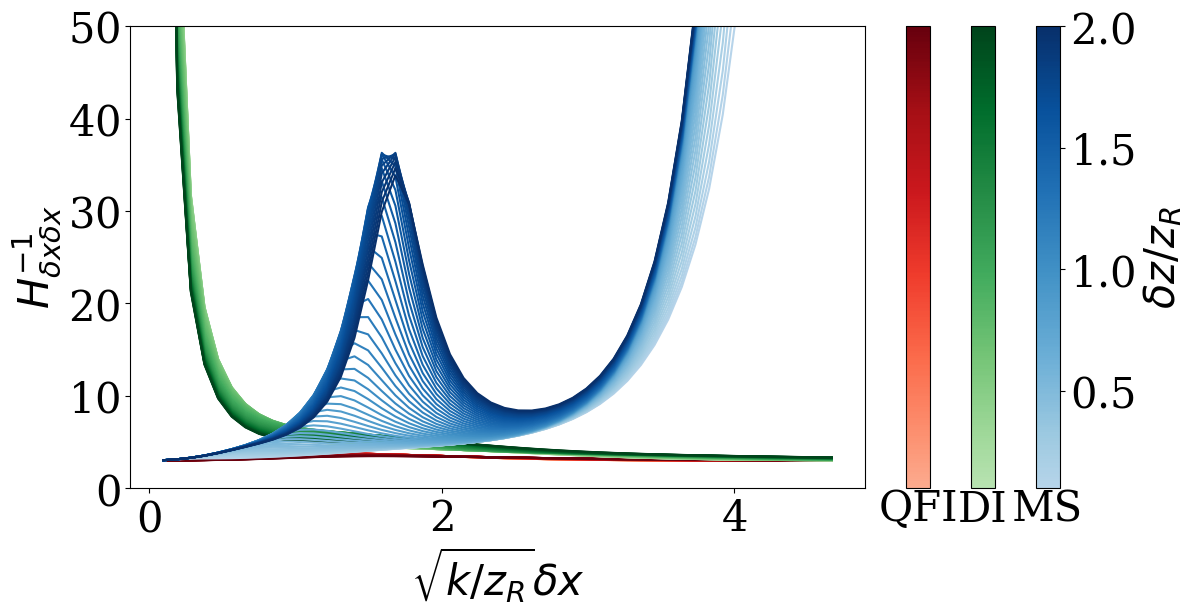

In [7]:
fig, axs = create_fig_and_ax(3)
qfi_cm = plot_individual_fi(
    fig, axs, qfi_inv_[:, :, 0, 0], x_range, p_range, "Reds", 1, "QFI"
)
di_cm = plot_individual_fi(
    fig, axs, fi_di_inv_[:, :, 0, 0], x_range, p_range, "Greens", 2, "DI"
)
ms_cm = plot_individual_fi(
    fig, axs, fi_ms_inv_[:, :, 0, 0], x_range, p_range, "Blues", 3, "MS", False
)

axs[0].set_ylim(0, 50)
axs[3].set_ylabel(r"$\delta z / z_R$")
axs[0].set_xlabel(r"$\sqrt{k/z_R} \delta x$")
axs[0].set_ylabel(r"$H^{-1}_{\delta x \delta x}$")

save_figure(fig, "s_param_covariance_optimal_remainder")
plt.show()

# p param

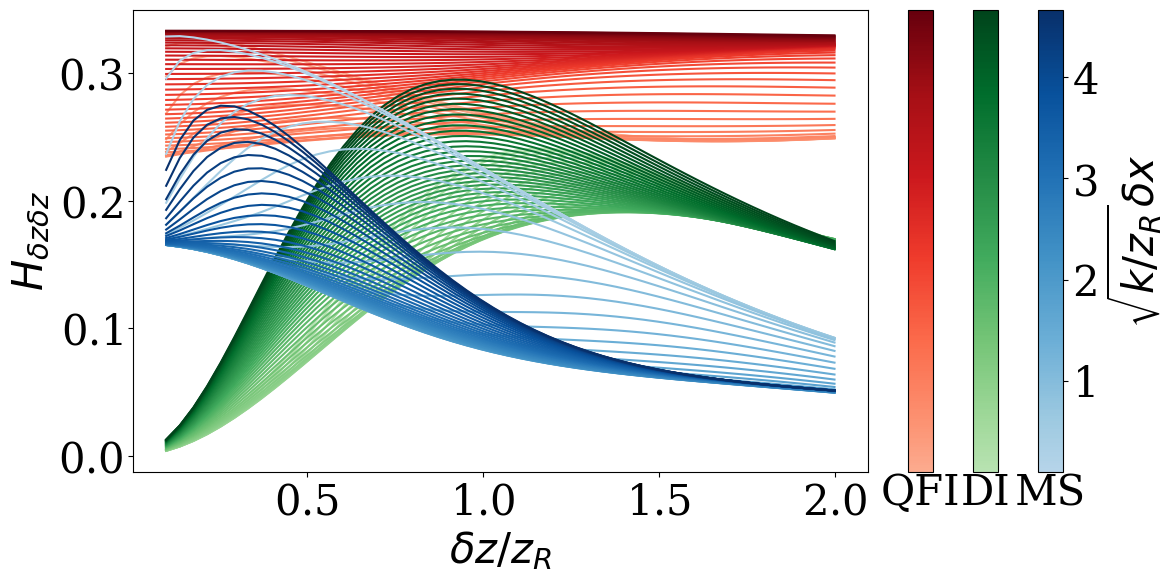

In [8]:
fig, axs = create_fig_and_ax(3)

qfi_cm = plot_individual_fi(
    fig, axs, np.transpose(qfi_[:, :, 1, 1]), p_range, x_range, "Reds", 1, "QFI"
)
di_cm = plot_individual_fi(
    fig, axs, np.transpose(fi_di_[:, :, 1, 1]), p_range, x_range, "Greens", 2, "DI"
)
qfi_cm = plot_individual_fi(
    fig,
    axs,
    np.transpose(np.sum(fi_ms_, axis=2)[:, :, 1, 1]),
    p_range,
    x_range,
    "Blues",
    3,
    "MS",
    False,
)

axs[3].set_ylabel(r"$\sqrt{k/z_R} \delta x$")
axs[0].set_xlabel(r"$\delta z / z_R$")
axs[0].set_ylabel(r"$H_{\delta z \delta z}$")

save_figure(fig, "p_param_fi_comparison_optimal_remainder")
plt.show()

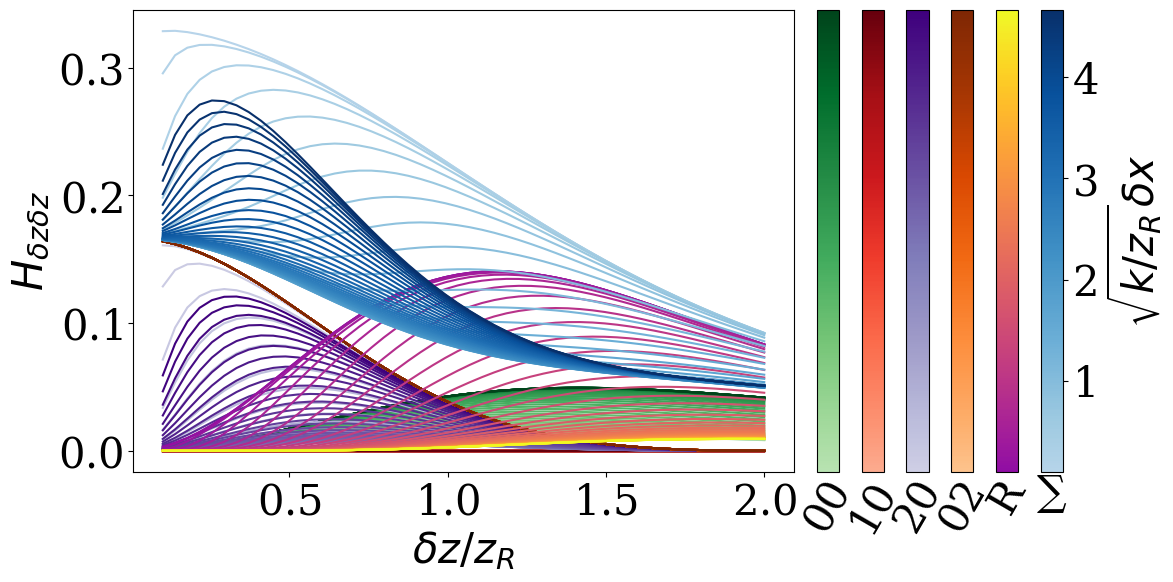

In [9]:
good_cmaps = filter_pub_friendly_continuous()
IMPORTANT_MODES = ((0, 0), (1, 0), (2, 0), (0, 2))

n_axes = len(IMPORTANT_MODES) + 1
fig, axs = create_fig_and_ax(n_axes + 1)

for idx, mode in enumerate(IMPORTANT_MODES):
    (i, j) = mode
    plot_individual_fi(
        fig,
        axs,
        np.transpose(fi_ms_[:, :, idx, 1, 1]),
        p_range,
        x_range,
        good_cmaps[idx],
        idx + 1,
        f"{i}{j}",
        rotation=60,
    )

plot_individual_fi(
    fig,
    axs,
    np.transpose(fi_ms_[:, :, -1, 1, 1]),
    p_range,
    x_range,
    good_cmaps[len(IMPORTANT_MODES)],
    len(IMPORTANT_MODES) + 1,
    r"R",
    rotation=60,
)


plot_individual_fi(
    fig,
    axs,
    np.transpose(np.sum(fi_ms_, axis=2)[:, :, 1, 1]),
    p_range,
    x_range,
    good_cmaps[-1],
    n_axes + 1,
    "∑",
    False,
)


axs[n_axes + 1].set_ylabel(r"$\sqrt{k/z_R} \delta x$")
axs[0].set_xlabel(r"$\delta z / z_R$")
axs[0].set_ylabel(r"$H_{\delta z \delta z}$")

save_figure(fig, "p_param_individual_mode_contributions_optimal_remainder")
plt.show()

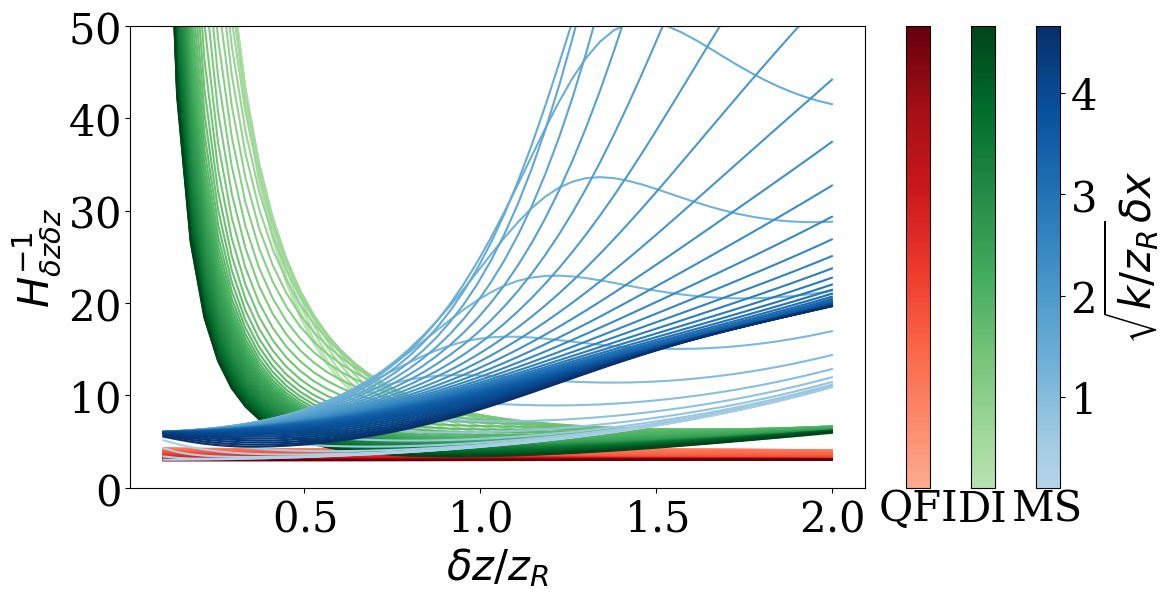

In [10]:
fig, axs = create_fig_and_ax(3)

qfi_cm = plot_individual_fi(
    fig, axs, np.transpose(qfi_inv_[:, :, 1, 1]), p_range, x_range, "Reds", 1, "QFI"
)
di_cm = plot_individual_fi(
    fig, axs, np.transpose(fi_di_inv_[:, :, 1, 1]), p_range, x_range, "Greens", 2, "DI"
)
qfi_cm = plot_individual_fi(
    fig,
    axs,
    np.transpose(fi_ms_inv_[:, :, 1, 1]),
    p_range,
    x_range,
    "Blues",
    3,
    "MS",
    False,
)

axs[0].set_ylim(0, 50)
axs[3].set_ylabel(r"$\sqrt{k/z_R} \delta x$")
axs[0].set_xlabel(r"$\delta z / z_R$")
axs[0].set_ylabel(r"$H^{-1}_{\delta z \delta z}$")

save_figure(fig, "p_param_covariance_optimal_remainder")
plt.show()